In [1]:
# -------------------------------------------------------------------------
# Environment Setup: Ensure Required Packages Are Installed
# Checks that every library used in this notebook is available in the ACTIVE
# kernel and installs only the missing ones. This makes "Run All" work no matter
# which Python environment / .venv the kernel was started from.
# -------------------------------------------------------------------------
import importlib
import importlib.util
import subprocess
import sys

# import name -> pip package name
required_packages = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}

missing_packages = [pip_name for module, pip_name in required_packages.items()
                    if importlib.util.find_spec(module) is None]

if missing_packages:
    print(f"Installing missing packages into {sys.executable}: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

All required packages are already installed.


# Model Training & Evaluation: Gaussian Naïve Bayes

**Team Member:** Mustafa

This notebook trains the probabilistic baseline model (Gaussian Naïve Bayes) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model strictly on the Validation set to avoid data leakage before final testing.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

In [2]:
# Import necessary libraries for data manipulation and mathematical operations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import the Gaussian Naïve Bayes algorithm and evaluation metrics from scikit-learn
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configure visual aesthetics for professional graphing
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 1. Data Loading
We load the strictly partitioned subsets from the `Data/` directory. For this iteration, we only use `X_train` / `y_train` for model fitting, and `X_val` / `y_val` for intermediate evaluation.

In [3]:
# -------------------------------------------------------------------------
# Load Processed Training and Validation Sets
# -------------------------------------------------------------------------
# Define the relative path to the preprocessed data directory
# Resolve the Data directory dynamically so the notebook runs whether the working
# directory is the project root or the notebooks/ folder (same logic as data_cleaning_merged)
from pathlib import Path
data_dir = Path.cwd() / "Data"
if not data_dir.exists():
    data_dir = (Path.cwd() / ".." / "Data").resolve()
base_path = f"{data_dir.as_posix()}/"

# Load the predictor features (X) for the training subset
X_train = pd.read_csv(f"{base_path}processed_X_train.csv")

# Load the target variable (y) for the training subset, isolating just the label column
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

# Load the predictor features (X) for the validation subset
X_val = pd.read_csv(f"{base_path}processed_X_val.csv")

# Load the target variable (y) for the validation subset, isolating just the label column
y_val = pd.read_csv(f"{base_path}processed_y_val.csv")['Layoff_Risk']

# Print the dimensionality to verify successful loading
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Validation set: {X_val.shape[0]:,} rows")

Training set: 14,000 rows
Validation set: 3,000 rows


In [4]:
# -------------------------------------------------------------------------
# Dataset Verification: Feature Set & Class Balance
# Confirms that the newly engineered 5-feature pipeline (11 predictors after
# one-hot encoding) was loaded correctly and establishes the majority-class baseline.
# -------------------------------------------------------------------------
print("--- PREDICTOR COLUMNS LOADED (X_train) ---")
for idx, col in enumerate(X_train.columns, start=1):
    print(f"{idx:>2}. {col}")
print(f"\nTotal predictors: {X_train.shape[1]}")

# Confirm train and validation partitions share an identical schema
assert list(X_train.columns) == list(X_val.columns), "Schema mismatch between train and validation sets!"
print("Schema check passed: train and validation columns are identical.")

# Verify there are no missing values that would break model fitting
print(f"Missing values in X_train: {int(X_train.isnull().sum().sum())} | X_val: {int(X_val.isnull().sum().sum())}")

# Class distribution and majority-class baseline accuracy
class_label_map = {0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'}
class_dist = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Val Count': y_val.value_counts().sort_index(),
    'Val (%)': (y_val.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index=class_label_map)
print("\n--- CLASS DISTRIBUTION ---")
display(class_dist)

# A model that always predicts the most frequent training class sets the floor any real model must beat
majority_class = y_train.value_counts().idxmax()
baseline_acc = (y_val == majority_class).mean()
print(f"Majority-class baseline accuracy on validation: {baseline_acc:.4f}")

--- PREDICTOR COLUMNS LOADED (X_train) ---
 1. Years_of_Experience
 2. Routine_Task_Percentage
 3. Tasks_Automated_Percentage
 4. Number_of_AI_Tools_Used
 5. Industry_Education
 6. Industry_Finance
 7. Industry_Healthcare
 8. Industry_Logistics
 9. Industry_Manufacturing
10. Industry_Retail
11. Industry_Telecom

Total predictors: 11
Schema check passed: train and validation columns are identical.
Missing values in X_train: 0 | X_val: 0

--- CLASS DISTRIBUTION ---


,Train Count,Train (%),Val Count,Val (%)
Layoff_Risk,,,,
Low (0),4621,33.01,990,33.0
Medium (1),4621,33.01,990,33.0
High (2),4758,33.99,1020,34.0


Majority-class baseline accuracy on validation: 0.3400


> **Methodological Rule — Zero-Leakage Training:**
> The model is exposed solely to the 14,000 training records. Evaluation is conducted solely against the 3,000 validation records. The test set remains completely unseen.

## 2. Model Initialization and Training

Gaussian Naïve Bayes models each predictor within each class as a normal distribution and combines them under the assumption of **conditional independence**. Two properties of our feature set are worth noting up front: (1) `Routine_Task_Percentage` and `Tasks_Automated_Percentage` are strongly correlated ($r = 0.89$), which violates the independence assumption, and (2) the 7 `Industry_*` one-hot indicators are binary rather than Gaussian. Both can limit the model, so this notebook serves as a probabilistic baseline against which Gradient Boosting is compared.

In [5]:
# -------------------------------------------------------------------------
# Fit Gaussian Naïve Bayes
# -------------------------------------------------------------------------
# Initialize the Gaussian Naïve Bayes model. 
# This model assumes features follow a normal distribution and are conditionally independent.
gnb = GaussianNB()

# Fit the model strictly to the training data. This calculates the prior probabilities 
# and class-conditional likelihoods for each feature based ONLY on X_train and y_train.
gnb.fit(X_train, y_train)

print("Gaussian Naïve Bayes training completed successfully!")

Gaussian Naïve Bayes training completed successfully!


In [6]:
# -------------------------------------------------------------------------
# Overfitting Check: Training vs. Validation Accuracy
# Naïve Bayes has very low capacity, so train and validation accuracy should be close.
# -------------------------------------------------------------------------
train_acc = accuracy_score(y_train, gnb.predict(X_train))
val_acc = accuracy_score(y_val, gnb.predict(X_val))

print(f"Training Accuracy:   {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Generalization Gap (Train - Val): {train_acc - val_acc:+.4f}")

# Learned class prior probabilities P(class), estimated from X_train/y_train only
print("\n--- LEARNED CLASS PRIORS ---")
display(pd.Series(gnb.class_prior_, index=['Low (0)', 'Medium (1)', 'High (2)'], name='Prior').round(4).to_frame())

Training Accuracy:   0.7236
Validation Accuracy: 0.7303
Generalization Gap (Train - Val): -0.0067

--- LEARNED CLASS PRIORS ---


,Prior
Low (0),0.3301
Medium (1),0.3301
High (2),0.3399


## 3. Validation Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [7]:
# -------------------------------------------------------------------------
# Predict on Validation Set
# -------------------------------------------------------------------------
# Generate predicted class labels for the validation subset
y_pred = gnb.predict(X_val)

# Calculate the overall proportion of correct predictions across all classes
acc = accuracy_score(y_val, y_pred)
print(f"Validation Accuracy: {acc:.4f}\n")

# Generate a confusion matrix to evaluate class-level true positives, false positives, etc.
cm = confusion_matrix(y_val, y_pred)

# Define the categorical class labels for clean iteration and printing
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

# Iterate through each unique class to calculate One-vs-Rest metrics
for i, label in enumerate(classes):
    # True Positives: diagonal element for the current class
    tp = cm[i, i]
    
    # False Negatives: sum of actual class row minus true positives
    fn = cm[i, :].sum() - tp
    
    # False Positives: sum of predicted class column minus true positives
    fp = cm[:, i].sum() - tp
    
    # True Negatives: total observations minus (TP + FP + FN)
    tn = cm.sum() - (tp + fn + fp)
    
    # Calculate Sensitivity (Recall): True Positives / Actual Positives
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Calculate Specificity (True Negative Rate): True Negatives / Actual Negatives
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Append to lists so we can calculate macro averages later
    sensitivities.append(sens)
    specificities.append(spec)
    
    # Print the per-class results
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

# Calculate and print the unweighted macro averages across all three classes
print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Validation Accuracy: 0.7303

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.8485
  - Specificity (TNR):    0.8672
Medium (1):
  - Sensitivity (Recall): 0.5333
  - Specificity (TNR):    0.8328
High (2):
  - Sensitivity (Recall): 0.8069
  - Specificity (TNR):    0.8960

--- Macro Averages ---
Macro Sensitivity: 0.7296
Macro Specificity: 0.8653


In [8]:
# -------------------------------------------------------------------------
# Consolidated Per-Class Metrics Table & scikit-learn Classification Report
# Combines Sensitivity, Specificity, and Precision for every class, followed
# by the standard classification report (precision / recall / F1 / support).
# -------------------------------------------------------------------------
# Precision = TP / (TP + FP) -> diagonal of the confusion matrix divided by predicted-class totals
precisions = np.diag(cm) / cm.sum(axis=0)

metrics_summary = pd.DataFrame({
    'Sensitivity (Recall)': sensitivities,
    'Specificity (TNR)': specificities,
    'Precision': precisions
}, index=class_names).round(4)
metrics_summary.loc['Macro Average'] = metrics_summary.mean().round(4)

print("--- PER-CLASS METRICS SUMMARY (VALIDATION SET) ---")
display(metrics_summary)

print(f"\nOverall Validation Accuracy: {acc:.4f}")
print("\n--- SCIKIT-LEARN CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred, target_names=class_names, digits=4))

--- PER-CLASS METRICS SUMMARY (VALIDATION SET) ---


,Sensitivity (Recall),Specificity (TNR),Precision
Low (0),0.8485,0.8672,0.7588
Medium (1),0.5333,0.8328,0.6111
High (2),0.8069,0.8960,0.7998
Macro Average,0.7296,0.8653,0.7232



Overall Validation Accuracy: 0.7303

--- SCIKIT-LEARN CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Low (0)     0.7588    0.8485    0.8011       990
  Medium (1)     0.6111    0.5333    0.5696       990
    High (2)     0.7998    0.8069    0.8033      1020

    accuracy                         0.7303      3000
   macro avg     0.7232    0.7296    0.7247      3000
weighted avg     0.7240    0.7303    0.7255      3000



> **Empirical Takeaway — Probabilistic Performance:**
> Gaussian Naïve Bayes achieves a **validation accuracy of 73.03%** (vs. a 34.00% majority-class baseline and roughly 42–43% with the earlier demographic-only features), with macro sensitivity **0.7296** and macro specificity **0.8653**. Performance is asymmetric across classes: **Low Risk** has the highest recall (**0.8485**) and **High Risk** has the highest precision (**0.7998**) and specificity (**0.8960**), while **Medium Risk** is the clear weak point (sensitivity only **0.5333**, F1 **0.5696**) because the model frequently assigns middle-tier workers to the adjacent extreme tiers. Training and validation accuracy are nearly identical (**72.36% vs. 73.03%**), confirming the low-capacity model neither over- nor under-fits relative to its assumptions. It trails Gradient Boosting by about **1.6 accuracy points**, consistent with its conditional-independence assumption being violated by the strongly correlated routine-task and automation features.

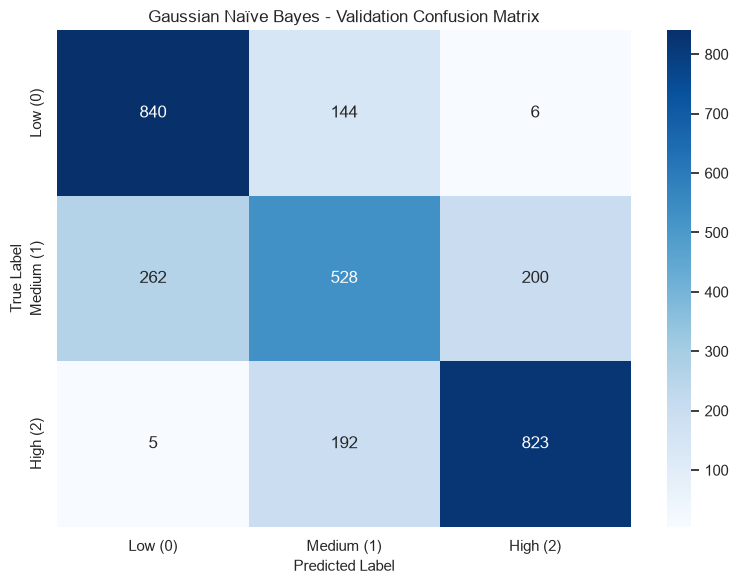

In [9]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
# Create a matplotlib figure to host the seaborn heatmap
plt.figure(figsize=(8, 6))

# Draw the heatmap, annotating cells with raw counts (fmt='d')
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)

# Add axis labels and title for academic clarity
plt.title("Gaussian Naïve Bayes - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Use tight_layout to prevent clipping of labels during image export
plt.tight_layout()

# Display the figure inline
plt.show()

## 4. Learned Class-Conditional Feature Means

Gaussian Naïve Bayes stores, for every class, the mean of each predictor (in standardized units for the numeric features, and as the class-conditional proportion for the one-hot industry indicators). Comparing these means shows which features the model uses to distinguish the risk tiers.

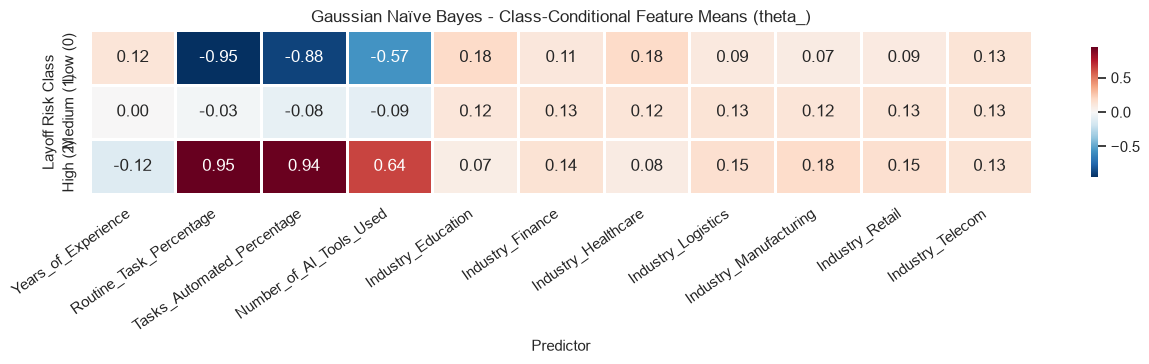

--- CLASS-CONDITIONAL MEANS TABLE ---


,Years_of_Experience,Routine_Task_Percentage,Tasks_Automated_Percentage,Number_of_AI_Tools_Used,Industry_Education,Industry_Finance,Industry_Healthcare,Industry_Logistics,Industry_Manufacturing,Industry_Retail,Industry_Telecom
Low (0),0.123,-0.950,-0.883,-0.571,0.184,0.106,0.179,0.094,0.075,0.088,0.128
Medium (1),0.002,-0.027,-0.080,-0.091,0.117,0.132,0.123,0.129,0.119,0.127,0.126
High (2),-0.122,0.949,0.936,0.643,0.073,0.140,0.076,0.150,0.175,0.153,0.132


In [10]:
# -------------------------------------------------------------------------
# Class-Conditional Feature Means (theta_)
# Rows = classes, columns = predictors. Numeric features are in z-score units.
# -------------------------------------------------------------------------
theta_df = pd.DataFrame(
    gnb.theta_,
    index=['Low (0)', 'Medium (1)', 'High (2)'],
    columns=X_train.columns
)

plt.figure(figsize=(13, 3.8))
sns.heatmap(theta_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.8, cbar_kws={"shrink": 0.8})
plt.title("Gaussian Naïve Bayes - Class-Conditional Feature Means (theta_)")
plt.xlabel("Predictor")
plt.ylabel("Layoff Risk Class")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

print("--- CLASS-CONDITIONAL MEANS TABLE ---")
display(theta_df.round(3))

> **Empirical Takeaway — How Naïve Bayes Separates the Tiers:**
> The class-conditional means show a near-symmetric ordering on the three workload features. Standardized `Routine_Task_Percentage` averages **−0.950** for Low Risk, **−0.027** for Medium and **+0.949** for High; `Tasks_Automated_Percentage` follows (**−0.883 / −0.080 / +0.936**), and `Number_of_AI_Tools_Used` (**−0.571 / −0.091 / +0.643**). `Years_of_Experience` shows only a small gradient (**+0.123 / +0.002 / −0.122**), confirming its secondary role. Industry indicators differ across classes mainly for Education and Healthcare (e.g., 18.4% / 17.9% of Low Risk workers vs. 7.3% / 7.6% of High Risk) and Manufacturing (7.5% Low vs. 17.5% High). Because the Medium class mean sits almost exactly at the global mean (≈ 0) on every numeric feature, a symmetric Gaussian has little to distinguish it from the tails of its neighbours—which directly explains its low recall of 0.5333.